# Rumor Spread Using Differential Equations

This notebook models rumor spread through a university population using the logistic differential equation:

$$\frac{dR}{dt}=kR(N-R),\qquad R(0)=R_0.$$

For $N=1000$, $R_0=10$, and $k=0.002$, the analytical solution is

$$R(t)=\frac{1000}{1+99e^{-2t}}.$$

**Assumptions:** fixed population, uniform mixing, constant sharing rate, and nobody forgets the rumor. These are illustrative assumptions, not measured data.

## 1. Install packages (run once if needed)

In [1]:
%mamba install numpy scipy pandas matplotlib

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.645 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


## 2. Imports and parameters

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

N = 1000
R0 = 10
k = 0.002
days = 7
assert N > 0 and 0 < R0 < N and k > 0


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

print("=" * 65)
print("       RUMOR SPREADING SIMULATION")
print("       Model Parameters Configuration")
print("=" * 65)

print("\nEnter the following simulation parameters.")
print("Press ENTER to use the default value shown.\n")


# Function to validate numerical inputs
def get_input(prompt, default, data_type, condition, error_message):
    while True:
        try:
            user_input = input(f"{prompt} [Default: {default}]: ").strip()

            value = default if user_input == "" else data_type(user_input)

            if condition(value):
                return value

            print(f"Invalid input: {error_message}\n")

        except ValueError:
            print("Invalid input: Please enter a valid number.\n")


# 1. Total Population
N = get_input(
    prompt="1. Total Population (N)",
    default=1000,
    data_type=int,
    condition=lambda x: x > 1,
    error_message="Population must be greater than 1."
)

# 2. Initial Rumor Spreaders
R0 = get_input(
    prompt="2. Initial Number of Rumor Spreaders (R0)",
    default=10,
    data_type=int,
    condition=lambda x: 0 < x < N,
    error_message=f"Must be greater than 0 and less than {N}."
)

# 3. Rumor Transmission Rate
k = get_input(
    prompt="3. Rumor Transmission Rate (k)",
    default=0.002,
    data_type=float,
    condition=lambda x: np.isfinite(x) and x > 0,
    error_message="Transmission rate must be a positive finite number."
)

# 4. Simulation Duration
days = get_input(
    prompt="4. Simulation Duration (Days)",
    default=7,
    data_type=int,
    condition=lambda x: x > 0,
    error_message="Duration must be greater than 0."
)


# Display the configured parameters
print("\n" + "=" * 65)
print("       SIMULATION PARAMETERS SUMMARY")
print("=" * 65)

parameters = pd.DataFrame({
    "Parameter": [
        "Total Population",
        "Initial Rumor Spreaders",
        "Initial Uninformed Population",
        "Rumor Transmission Rate",
        "Simulation Duration"
    ],
    "Symbol": ["N", "R0", "S0", "k", "days"],
    "Value": [
        N,
        R0,
        N - R0,
        k,
        days
    ]
})

display(parameters)

print("\nParameters validated successfully!")
print("The simulation is ready to run.")

       RUMOR SPREADING SIMULATION
       Model Parameters Configuration

Enter the following simulation parameters.
Press ENTER to use the default value shown.



1. Total Population (N) [Default: 1000]:  90
2. Initial Number of Rumor Spreaders (R0) [Default: 10]:  5
3. Rumor Transmission Rate (k) [Default: 0.002]:  0.5
4. Simulation Duration (Days) [Default: 7]:  1



       SIMULATION PARAMETERS SUMMARY


,Parameter,Symbol,Value
0,Total Population,N,90.0
1,Initial Rumor Spreaders,R0,5.0
2,Initial Uninformed Population,S0,85.0
3,Rumor Transmission Rate,k,0.5
4,Simulation Duration,days,1.0



Parameters validated successfully!
The simulation is ready to run.


## 3. Analytical and numerical solutions

In [10]:
def rumor_analytical(t, N=N, R0=R0, k=k):
    A = (N - R0) / R0
    return N / (1 + A * np.exp(-k * N * np.asarray(t)))

def rumor_ode(t, y):
    R = y[0]
    return [k * R * (N - R)]

t = np.linspace(0, days, 701)
solution = solve_ivp(rumor_ode, (0, days), [R0], t_eval=t,
                     rtol=1e-10, atol=1e-10)
assert solution.success, solution.message
analytical = rumor_analytical(t)
numerical = solution.y[0]
print(f'Maximum absolute difference: {np.max(np.abs(analytical-numerical)):.8f} students')

Maximum absolute difference: 0.00000002 students


## 4. Results for each day

In [11]:
day_points = np.arange(days + 1)
counts = rumor_analytical(day_points)
table = pd.DataFrame({
    'Day': day_points,
    'Students informed (expected)': np.round(counts, 2),
    'Students informed (rounded)': np.rint(counts).astype(int),
    'Percent informed': np.round(100 * counts / N, 2)
})
display(table)

,Day,Students informed (expected),Students informed (rounded),Percent informed
0,0,5.0,5,5.56
1,1,90.0,90,100.00


## 5. Plot both solutions

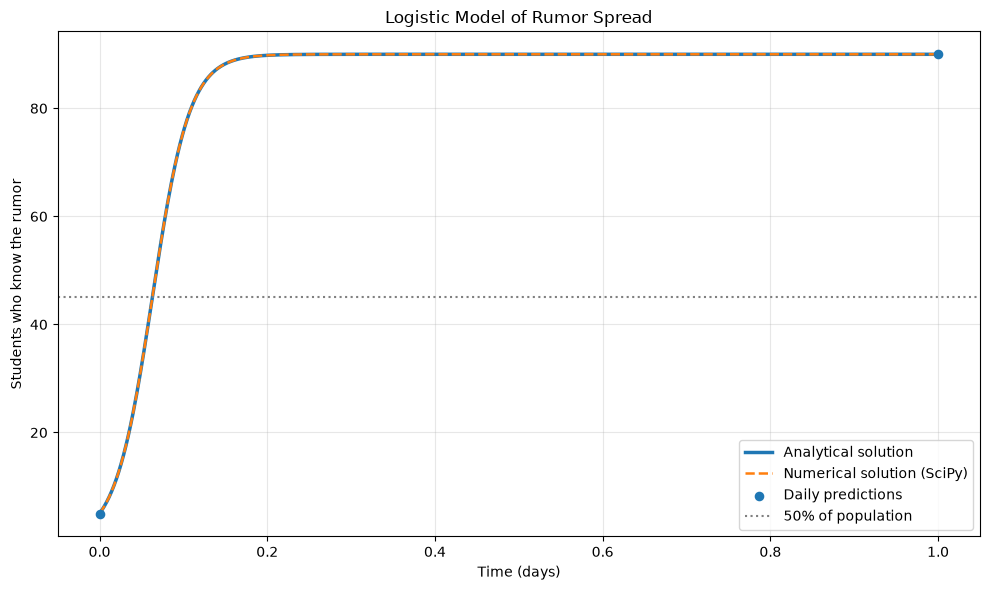

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(t, analytical, label='Analytical solution', linewidth=2.5)
plt.plot(t, numerical, '--', label='Numerical solution (SciPy)', linewidth=1.8)
plt.scatter(day_points, counts, s=35, zorder=3, label='Daily predictions')
plt.axhline(N/2, color='gray', linestyle=':', label='50% of population')
plt.xlabel('Time (days)')
plt.ylabel('Students who know the rumor')
plt.title('Logistic Model of Rumor Spread')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Time to reach 50% and 90%

In [13]:
def time_to_fraction(fraction, N=N, R0=R0, k=k):
    if not 0 < fraction < 1:
        raise ValueError('fraction must be between 0 and 1')
    target = fraction * N
    if target <= R0:
        return 0.0
    A = (N-R0)/R0
    return np.log(A * target / (N-target)) / (k*N)

for fraction in (0.5, 0.9):
    print(f'{fraction:.0%} reached after {time_to_fraction(fraction):.4f} days')

50% reached after 0.0630 days
90% reached after 0.1118 days


## 7. Rate of spread and maximum rate

Maximum rate: 1012.50 students/day
Time of maximum rate: 0.0630 days


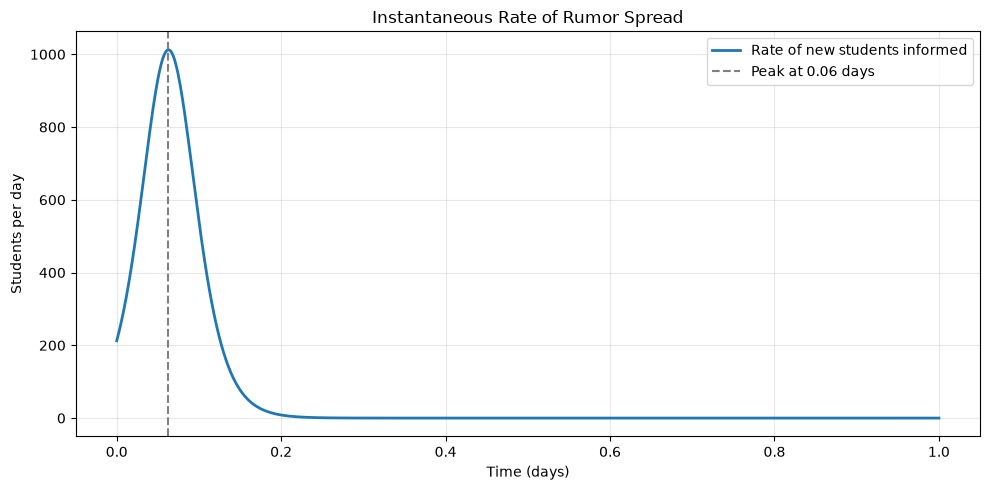

In [14]:
growth_rate = k * analytical * (N - analytical)
peak_time = time_to_fraction(0.5)
peak_rate = k * (N/2) * (N/2)
print(f'Maximum rate: {peak_rate:.2f} students/day')
print(f'Time of maximum rate: {peak_time:.4f} days')
plt.figure(figsize=(10, 5))
plt.plot(t, growth_rate, linewidth=2, label='Rate of new students informed')
plt.axvline(peak_time, linestyle='--', color='gray', label=f'Peak at {peak_time:.2f} days')
plt.xlabel('Time (days)')
plt.ylabel('Students per day')
plt.title('Instantaneous Rate of Rumor Spread')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Experiment with different spreading rates

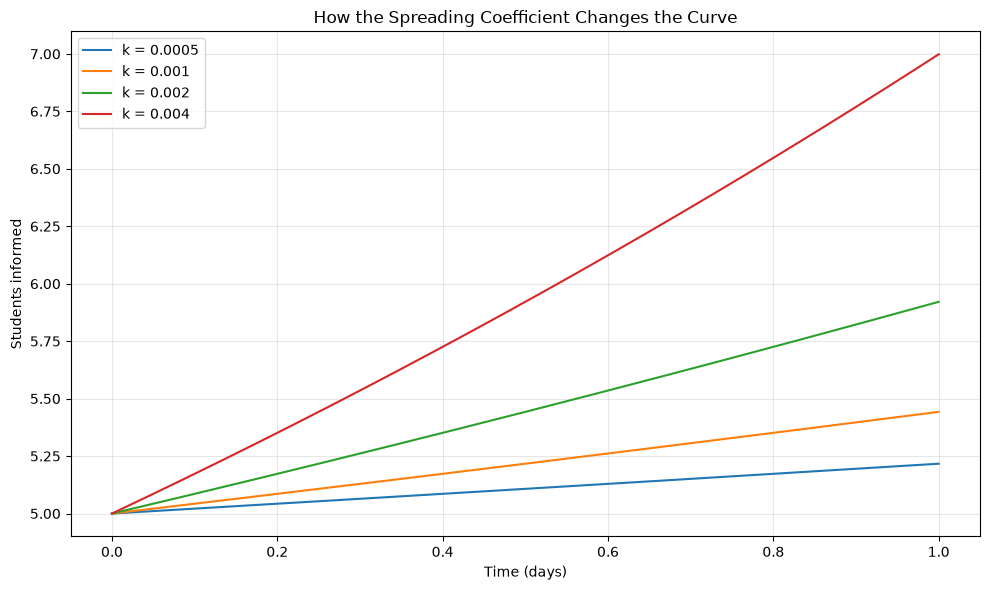

In [15]:
plt.figure(figsize=(10, 6))
for trial_k in (0.0005, 0.001, 0.002, 0.004):
    plt.plot(t, rumor_analytical(t, k=trial_k), label=f'k = {trial_k}')
plt.xlabel('Time (days)')
plt.ylabel('Students informed')
plt.title('How the Spreading Coefficient Changes the Curve')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Interpretation

- Initial spread is slow because few students know the rumor.
- Growth accelerates until approximately half the population is informed.
- The maximum **instantaneous** rate is 500 students/day; this is not the same as exactly 500 new students over a calendar day.
- Growth slows as the informed population approaches 1,000.
- The model approaches 1,000 asymptotically; it does not reach 1,000 exactly at a finite time.

**Note:** Results are continuous expected counts, so rounding is only for presentation. The model does not represent network structure, forgetting, or rumor correction.